In [1]:
# 1. Cài đặt thư viện cần thiết (Kaggle / Colab)
!pip install -q stardist csbdeep scikit-image tifffile pandas tabulate

In [2]:
# 2. Tìm thư mục StarDist_Dataset (tự động nhận diện Kaggle / Colab / Local)
import os
import subprocess
from pathlib import Path

def find_dataset_dir():
    candidates = [
        Path.cwd() / "StarDist_Dataset",
        Path.cwd() / "BTL_XLA_N3_2026" / "StarDist_Dataset",
        Path.cwd().parent / "StarDist_Dataset",
        Path("/kaggle/working/BTL_XLA_N3_2026/StarDist_Dataset"),
        Path("/content/BTL_XLA_N3_2026/StarDist_Dataset"),
        Path("/content/StarDist_Dataset"),
    ]
    for p in candidates:
        if (p / "experiments/pretrained_fluo/manifest.csv").exists():
            return p

    # Quét /kaggle/input nếu người dùng upload StarDist_Dataset thành Kaggle Dataset
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for manifest in kaggle_input.rglob("experiments/pretrained_fluo/manifest.csv"):
            return manifest.parents[2]

    # Nếu chưa có (vd: notebook mới trên Kaggle/Colab có Internet), clone từ GitHub nhóm
    repo_url = "https://github.com/Krinkin215/BTL_XLA_N3_2026.git"
    clone_target = Path.cwd() / "BTL_XLA_N3_2026"
    print(f"Chưa thấy dữ liệu cục bộ. Đang clone từ {repo_url}...")
    res = subprocess.run(["git", "clone", "--depth", "1", repo_url, str(clone_target)],
                         capture_output=True, text=True)
    if res.returncode == 0 and (clone_target / "StarDist_Dataset/experiments/pretrained_fluo/manifest.csv").exists():
        return clone_target / "StarDist_Dataset"

    raise FileNotFoundError(
        "Không tìm thấy thư mục StarDist_Dataset!\n"
        "- Nếu chạy trên Kaggle không Internet hoặc repo private: hãy Add Data (upload thư mục StarDist_Dataset thành Kaggle Dataset).\n"
        f"- Chi tiết lỗi git clone (nếu có): {res.stderr}"
    )

DATASET_DIR = find_dataset_dir()
print("Đang sử dụng DATASET_DIR:", DATASET_DIR)

Chưa thấy dữ liệu cục bộ. Đang clone từ https://github.com/Krinkin215/BTL_XLA_N3_2026.git...
Đang sử dụng DATASET_DIR: /kaggle/working/BTL_XLA_N3_2026/StarDist_Dataset


In [3]:
# 3. Đọc dữ liệu đã tiền xử lý từ manifest (không normalize lại, không fill_label_holes)
import numpy as np
import pandas as pd
from tifffile import imread

# Đặt False để khớp đúng protocol 20 val / 20 test trong Báo cáo mục 3.2 và config.json.
# Có thể đổi thành True nếu muốn mở rộng test sang toàn bộ 112 ảnh xám nền tối trong tập test đầy đủ.
USE_FULL_DARK_TEST = False

df_pre = pd.read_csv(DATASET_DIR / "experiments/pretrained_fluo/manifest.csv", keep_default_na=False)
val_df = df_pre[df_pre["split"] == "val"].reset_index(drop=True)

if USE_FULL_DARK_TEST:
    df_all = pd.read_csv(DATASET_DIR / "dataset_manifest.csv", keep_default_na=False)
    test_df = df_all[(df_all["split"] == "test") & (df_all["normalized_path"] != "")].reset_index(drop=True)
else:
    test_df = df_pre[df_pre["split"] == "test"].reset_index(drop=True)

def load_split(df):
    images, masks = [], []
    for _, row in df.iterrows():
        img = np.load(DATASET_DIR / row["normalized_path"]).astype(np.float32)
        msk = imread(DATASET_DIR / row["mask_path"])
        assert img.shape == msk.shape, f"Lệch kích thước ở {row['source_id']}: {img.shape} vs {msk.shape}"
        images.append(img)
        masks.append(msk)
    return images, masks

X_val, Y_val = load_split(val_df)
X_test, Y_test = load_split(test_df)

print(f"Tập Validation: {len(X_val)} ảnh | Tổng số nhân: {int(val_df['num_instances'].sum())} "
      f"(min={int(val_df['num_instances'].min())}, mean={val_df['num_instances'].mean():.2f}, max={int(val_df['num_instances'].max())})")
print(f"Tập Test      : {len(X_test)} ảnh | Tổng số nhân: {int(test_df['num_instances'].sum())} "
      f"(min={int(test_df['num_instances'].min())}, mean={test_df['num_instances'].mean():.2f}, max={int(test_df['num_instances'].max())})")
print(f"Kiểu dữ liệu ảnh: {X_test[0].dtype}, min={X_test[0].min():.4f}, max={X_test[0].max():.4f} | Nhãn: {Y_test[0].dtype}")

Tập Validation: 20 ảnh | Tổng số nhân: 862 (min=6, mean=43.10, max=191)
Tập Test      : 20 ảnh | Tổng số nhân: 984 (min=6, mean=49.20, max=375)
Kiểu dữ liệu ảnh: float32, min=0.0000, max=1.0000 | Nhãn: uint16


In [4]:
# 4. Cài đặt Otsu và Otsu + Watershed
from scipy import ndimage as ndi
from skimage.filters import gaussian, threshold_otsu
from skimage.morphology import binary_opening, disk, remove_small_objects
from skimage.measure import label
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

def otsu_seg(img, sigma=1.0, min_size=30):
    """Phương pháp 1: Otsu thuần (Semantic segmentation -> Connected Components)."""
    smoothed = gaussian(img, sigma=sigma)
    if float(smoothed.max() - smoothed.min()) <= 1e-8:
        empty = np.zeros(img.shape, dtype=bool)
        return np.zeros(img.shape, dtype=np.int32), empty
    thresh = threshold_otsu(smoothed)
    mask = smoothed > thresh
    mask = binary_opening(mask, disk(2))
    mask = remove_small_objects(mask, min_size=min_size)
    return label(mask), mask

def watershed_seg(img, sigma=1.0, min_size=30, min_distance=5):
    """Phương pháp 2: Otsu + Distance Transform + Watershed (Instance segmentation)."""
    lbl_mask, mask = otsu_seg(img, sigma=sigma, min_size=min_size)
    if not np.any(mask):
        return lbl_mask
    dist = ndi.distance_transform_edt(mask)
    coords = peak_local_max(dist, min_distance=min_distance, labels=lbl_mask)
    if len(coords) == 0:
        return lbl_mask
    markers = np.zeros(dist.shape, dtype=np.int32)
    markers[tuple(coords.T)] = np.arange(1, len(coords) + 1, dtype=np.int32)
    ws_labels = watershed(-dist, markers, mask=mask)
    return ws_labels

In [5]:
# 5. Tải mô hình StarDist Pretrained và chọn/kiểm chứng tham số trên Validation
from stardist.models import StarDist2D
from stardist.matching import matching_dataset

# 1. Mô hình StarDist pretrained
model_pre = StarDist2D.from_pretrained("2D_versatile_fluo")
print("Ngưỡng mặc định của 2D_versatile_fluo:", model_pre.thresholds)

# Tùy chọn tối ưu prob_thresh & nms_thresh trên tập Validation (theo mục 2.3 & 3.2 báo cáo)
OPTIMIZE_STARDIST_ON_VAL = True
if OPTIMIZE_STARDIST_ON_VAL:
    opt_thresh = model_pre.optimize_thresholds(X_val, Y_val)
    print("Ngưỡng StarDist tối ưu trên Validation:", model_pre.thresholds)

# 2. Chọn tham số Otsu & Watershed trên Validation (không chỉnh trên Test!)
best_otsu_cfg = {"sigma": 1.0, "min_size": 30}
best_otsu_ap = -1.0
for sigma in [0.8, 1.0, 1.5]:
    for min_size in [20, 30, 50]:
        preds_v = [otsu_seg(x, sigma=sigma, min_size=min_size)[0] for x in X_val]
        ap = matching_dataset(Y_val, preds_v, thresh=0.5, show_progress=False).accuracy
        if ap > best_otsu_ap:
            best_otsu_ap = ap
            best_otsu_cfg = {"sigma": sigma, "min_size": min_size}

best_ws_cfg = {"sigma": best_otsu_cfg["sigma"], "min_size": best_otsu_cfg["min_size"], "min_distance": 5}
best_ws_ap = -1.0
for sigma in [0.8, 1.0, 1.5]:
    for min_size in [20, 30, 50]:
        for min_dist in [3, 5, 7, 9]:
            preds_v = [watershed_seg(x, sigma=sigma, min_size=min_size, min_distance=min_dist) for x in X_val]
            ap = matching_dataset(Y_val, preds_v, thresh=0.5, show_progress=False).accuracy
            if ap > best_ws_ap:
                best_ws_ap = ap
                best_ws_cfg = {"sigma": sigma, "min_size": min_size, "min_distance": min_dist}

print(f"Otsu tốt nhất trên Val (AP@0.5={best_otsu_ap:.4f}): {best_otsu_cfg}")
print(f"Watershed tốt nhất trên Val (AP@0.5={best_ws_ap:.4f}): {best_ws_cfg}")

# (Tùy chọn) Mô hình tự huấn luyện nếu nhóm có weights trong thư mục models/
# model_trained = StarDist2D(None, name="stardist_btl", basedir="models")

Found model '2D_versatile_fluo' for 'StarDist2D'.
5320433/5320433 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.479071, nms_thresh=0.3.
Ngưỡng mặc định của 2D_versatile_fluo: Thresholds(prob=0.479071463157368, nms=0.3)


NMS threshold = 0.5:  80%|████████  | 16/20 [00:07<00:01,  2.14it/s, 0.476 -> 0.848]


Using optimized values: prob_thresh=0.475761, nms_thresh=0.3.
Ngưỡng StarDist tối ưu trên Validation: Thresholds(prob=0.47576063871383667, nms=0.3)
Otsu tốt nhất trên Val (AP@0.5=0.6677): {'sigma': 0.8, 'min_size': 20}
Watershed tốt nhất trên Val (AP@0.5=0.7237): {'sigma': 1.0, 'min_size': 30, 'min_distance': 9}


In [6]:
# 6. Đánh giá định lượng trên tập Test (Bảng 5.1)
import time

def evaluate_pipeline(name, predict_fn):
    print(f"Đang chạy đánh giá trên {len(X_test)} ảnh test: {name}...")
    start_time = time.time()
    preds = [predict_fn(x) for x in X_test]
    elapsed_time = (time.time() - start_time) / len(X_test)

    res_05 = matching_dataset(Y_test, preds, thresh=0.5, show_progress=False)
    res_07 = matching_dataset(Y_test, preds, thresh=0.7, show_progress=False)
    res_09 = matching_dataset(Y_test, preds, thresh=0.9, show_progress=False)

    return {
        "Phương pháp": name,
        "Precision": round(res_05.precision, 4),
        "Recall": round(res_05.recall, 4),
        "F1": round(res_05.f1, 4),
        "AP@0.5": round(res_05.accuracy, 4),
        "AP@0.7": round(res_07.accuracy, 4),
        "AP@0.9": round(res_09.accuracy, 4),
        "Thời gian/ảnh (s)": round(elapsed_time, 4),
    }, preds

def run_otsu(img):
    return otsu_seg(img, **best_otsu_cfg)[0]

def run_watershed(img):
    return watershed_seg(img, **best_ws_cfg)

def run_stardist_pre(img):
    labels, _ = model_pre.predict_instances(img)
    return labels

# Warm-up 1 lần nhỏ cho TensorFlow/StarDist để đo thời gian suy luận chính xác hơn
_ = model_pre.predict_instances(X_val[0])

results = []
row_otsu, preds_otsu = evaluate_pipeline("Otsu", run_otsu)
row_ws, preds_ws = evaluate_pipeline("Otsu + Watershed", run_watershed)
row_star, preds_star_pre = evaluate_pipeline("StarDist (huấn luyện sẵn)", run_stardist_pre)
results.extend([row_otsu, row_ws, row_star])

df_results = pd.DataFrame(results)
df_results.to_csv("bang_5_1_ket_qua.csv", index=False, encoding="utf-8-sig")
print(f"\n=== BẢNG 5.1: KẾT QUẢ TRÊN {len(X_test)} ẢNH TEST (IoU=0.5) ===")
print(df_results.to_markdown(index=False))

Đang chạy đánh giá trên 20 ảnh test: Otsu...
Đang chạy đánh giá trên 20 ảnh test: Otsu + Watershed...
Đang chạy đánh giá trên 20 ảnh test: StarDist (huấn luyện sẵn)...

=== BẢNG 5.1: KẾT QUẢ TRÊN 20 ẢNH TEST (IoU=0.5) ===
| Phương pháp               |   Precision |   Recall |     F1 |   AP@0.5 |   AP@0.7 |   AP@0.9 |   Thời gian/ảnh (s) |
|:--------------------------|------------:|---------:|-------:|---------:|---------:|---------:|--------------------:|
| Otsu                      |      0.8805 |   0.4268 | 0.5749 |   0.4035 |   0.3294 |   0.1697 |              0.0131 |
| Otsu + Watershed          |      0.8296 |   0.4502 | 0.5837 |   0.4121 |   0.3446 |   0.1777 |              0.0403 |
| StarDist (huấn luyện sẵn) |      0.901  |   0.7673 | 0.8288 |   0.7076 |   0.491  |   0.1877 |              0.2205 |


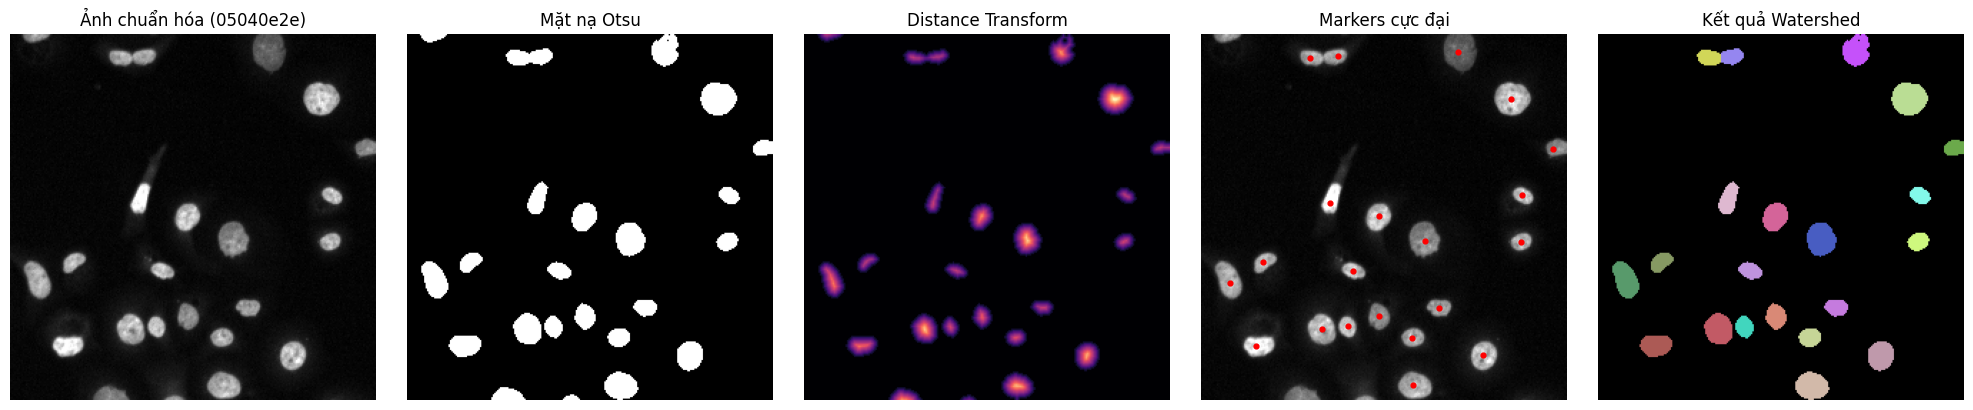

In [7]:
# 7. Hình 2.8: Minh họa các bước Otsu -> Distance Transform -> Markers -> Watershed
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def make_label_cmap(n_colors=256, seed=42):
    rng = np.random.default_rng(seed)
    colors = rng.uniform(0.25, 1.0, size=(n_colors, 3))
    colors[0] = [0.0, 0.0, 0.0]  # Nền 0 luôn màu đen
    return ListedColormap(colors)

def colorize_labels(lbl, seed=42):
    if lbl.max() == 0:
        return np.zeros((*lbl.shape, 3), dtype=np.float32)
    rng = np.random.default_rng(seed)
    palette = rng.uniform(0.25, 1.0, size=(int(lbl.max()) + 1, 3))
    palette[0] = [0.0, 0.0, 0.0]
    return palette[lbl]

# Chọn 1 ảnh mật độ trung bình trong tập test
idx_step = int(np.argsort(test_df["num_instances"].values)[len(test_df) // 2])
sample_img = X_test[idx_step]
sample_lbl_mask, sample_mask = otsu_seg(sample_img, **best_otsu_cfg)
sample_dist = ndi.distance_transform_edt(sample_mask)
sample_coords = peak_local_max(sample_dist, min_distance=best_ws_cfg["min_distance"], labels=sample_lbl_mask)
sample_markers = np.zeros(sample_dist.shape, dtype=np.int32)
if len(sample_coords) > 0:
    sample_markers[tuple(sample_coords.T)] = np.arange(1, len(sample_coords) + 1)
sample_ws = watershed(-sample_dist, sample_markers, mask=sample_mask)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
axes[0].imshow(sample_img, cmap="gray"); axes[0].set_title(f"Ảnh chuẩn hóa ({test_df.iloc[idx_step]['source_id'][:8]})")
axes[1].imshow(sample_mask, cmap="gray"); axes[1].set_title("Mặt nạ Otsu")
axes[2].imshow(sample_dist, cmap="magma"); axes[2].set_title("Distance Transform")
axes[3].imshow(sample_img, cmap="gray")
if len(sample_coords) > 0:
    axes[3].scatter(sample_coords[:, 1], sample_coords[:, 0], c="red", s=12)
axes[3].set_title("Markers cực đại")
axes[4].imshow(colorize_labels(sample_ws)); axes[4].set_title("Kết quả Watershed")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("hinh_2_8_watershed_steps.png", dpi=300, bbox_inches="tight")
plt.show()

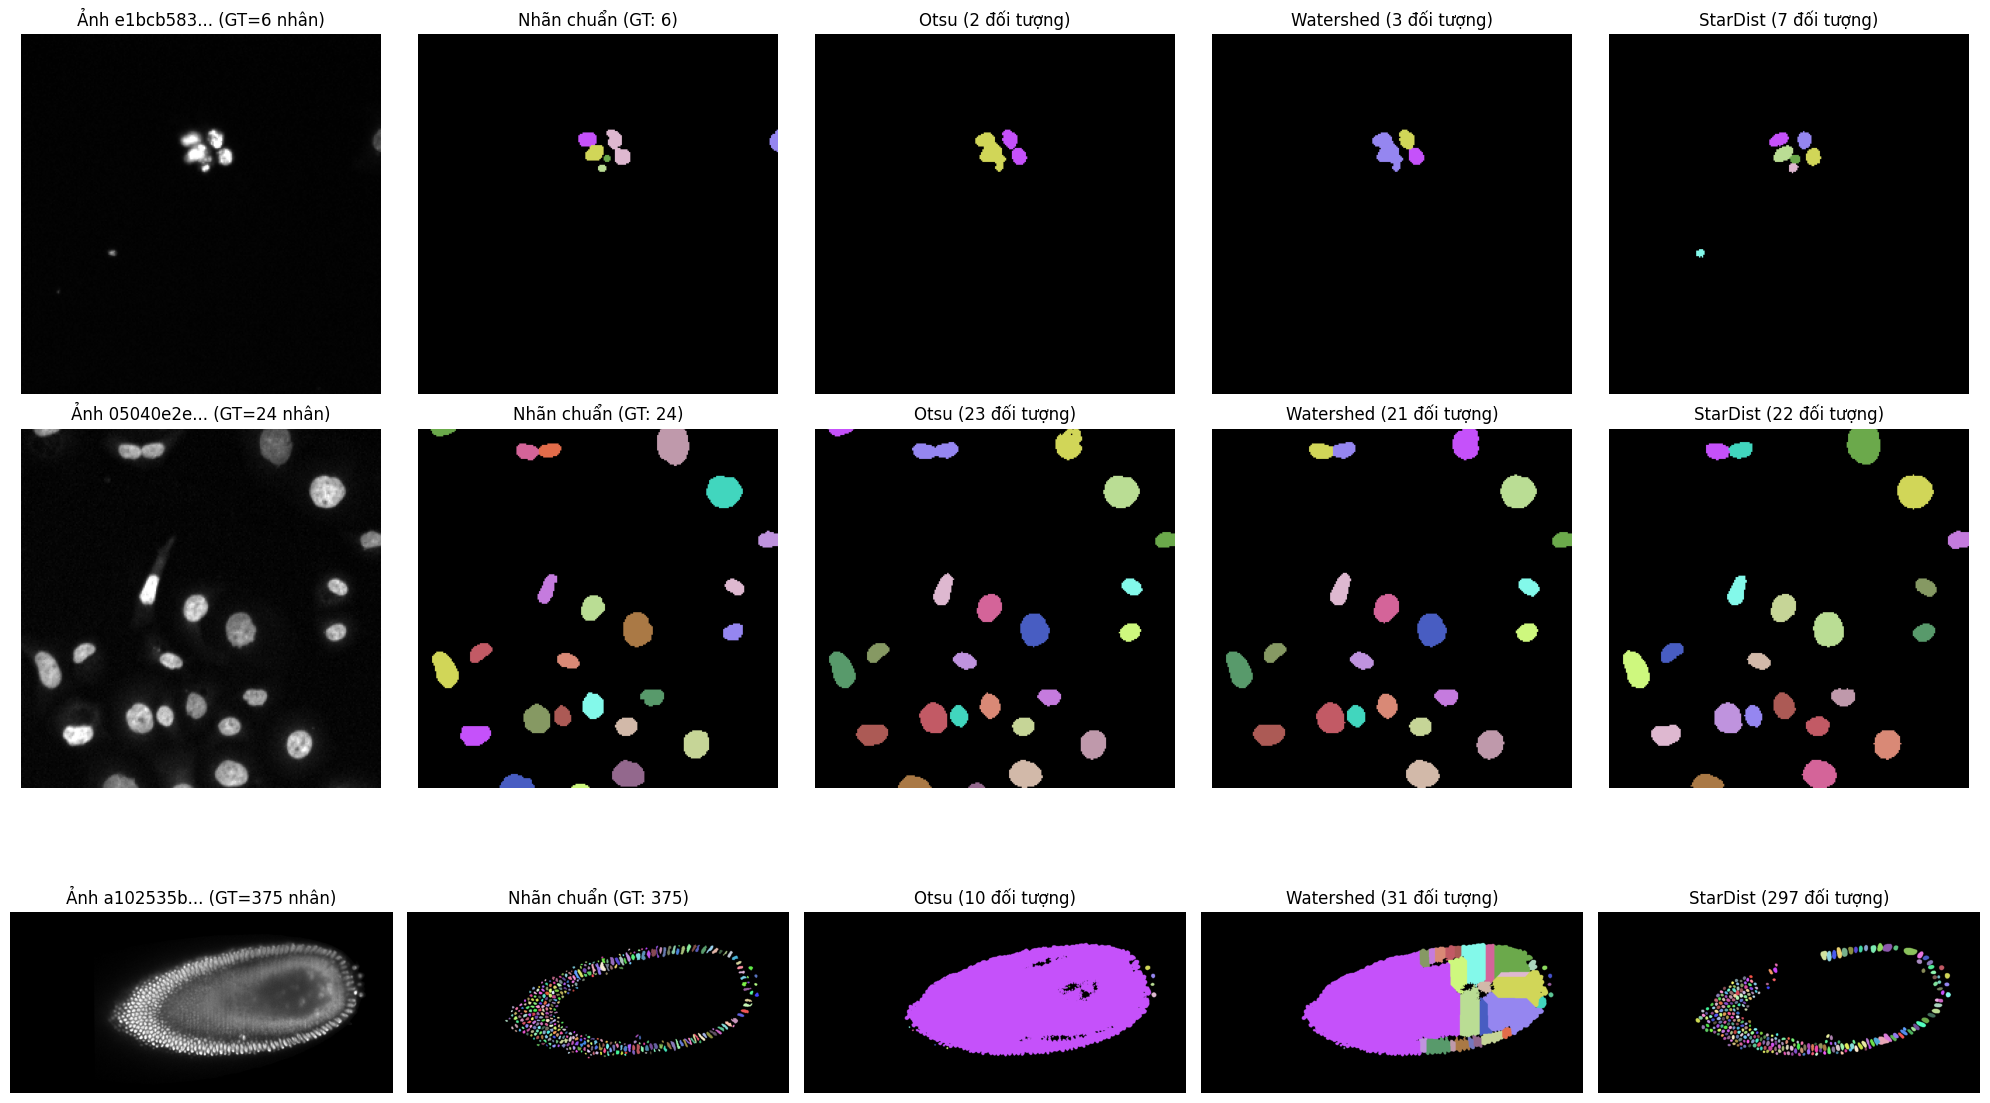

Các ID ảnh dùng cho Hình 5.2: ['e1bcb583985325d0ef5f3ef52957d0371c96d4af767b13e48102bca9d5351a9b', '05040e2e959c3f5632558fc9683fec88f0010026c555b499066346f67fdd0e13', 'a102535b0e88374bea4a1cfd9ee7cb3822ff54f4ab2a9845d428ec22f9ee2288']


In [8]:
# 8. Hình 5.2: So sánh định tính trên 3 ảnh Test tiêu biểu (thưa, trung bình, dày đặc)
sorted_order = np.argsort(test_df["num_instances"].values)
test_indices = [
    int(sorted_order[0]),                      # Thưa (ít nhân nhất)
    int(sorted_order[len(sorted_order) // 2]), # Mật độ trung bình
    int(sorted_order[-1]),                     # Dày đặc (nhiều nhân nhất)
]

fig, axes = plt.subplots(3, 5, figsize=(20, 12))
for row, i in enumerate(test_indices):
    sid = test_df.iloc[i]["source_id"]
    n_nuc = int(test_df.iloc[i]["num_instances"])
    img = X_test[i]
    gt = Y_test[i]
    pred_o = preds_otsu[i]
    pred_w = preds_ws[i]
    pred_s = preds_star_pre[i]

    axes[row, 0].imshow(img, cmap="gray")
    axes[row, 0].set_title(f"Ảnh {sid[:8]}... (GT={n_nuc} nhân)")
    axes[row, 1].imshow(colorize_labels(gt))
    axes[row, 1].set_title(f"Nhãn chuẩn (GT: {int(gt.max())})")
    axes[row, 2].imshow(colorize_labels(pred_o))
    axes[row, 2].set_title(f"Otsu ({int(pred_o.max())} đối tượng)")
    axes[row, 3].imshow(colorize_labels(pred_w))
    axes[row, 3].set_title(f"Watershed ({int(pred_w.max())} đối tượng)")
    axes[row, 4].imshow(colorize_labels(pred_s))
    axes[row, 4].set_title(f"StarDist ({int(pred_s.max())} đối tượng)")

    for col in range(5):
        axes[row, col].axis("off")

plt.tight_layout()
plt.savefig("hinh_5_2_so_sanh_dinh_tinh.png", dpi=300, bbox_inches="tight")
plt.show()
print("Các ID ảnh dùng cho Hình 5.2:", [test_df.iloc[i]["source_id"] for i in test_indices])

Đang quét ngưỡng IoU từ 0.50 đến 0.90...


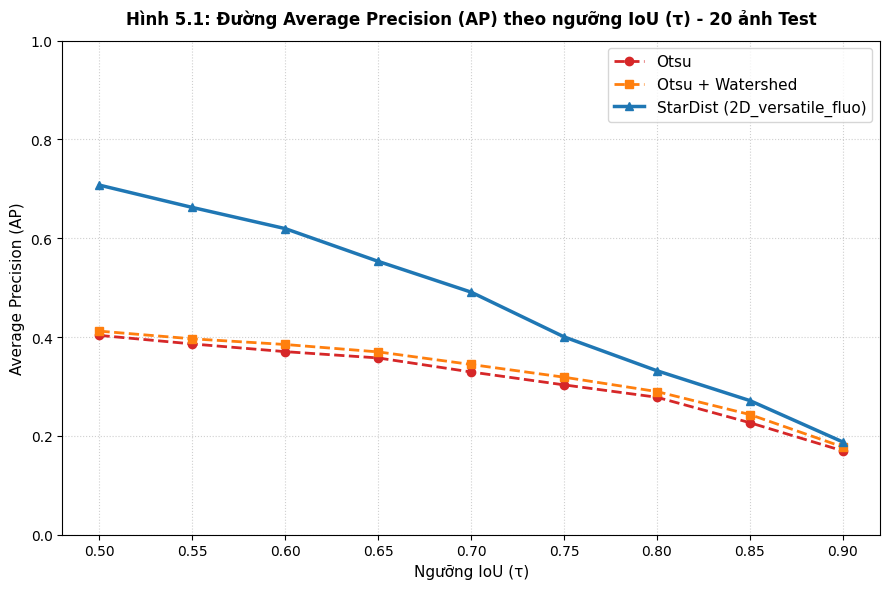

In [9]:
# 9. Hình 5.1: Đường Average Precision (AP) theo ngưỡng IoU (τ)
taus = np.arange(0.5, 0.95, 0.05)
ap_otsu, ap_watershed, ap_stardist_pre = [], [], []

print("Đang quét ngưỡng IoU từ 0.50 đến 0.90...")
for t in taus:
    ap_otsu.append(matching_dataset(Y_test, preds_otsu, thresh=float(t), show_progress=False).accuracy)
    ap_watershed.append(matching_dataset(Y_test, preds_ws, thresh=float(t), show_progress=False).accuracy)
    ap_stardist_pre.append(matching_dataset(Y_test, preds_star_pre, thresh=float(t), show_progress=False).accuracy)

plt.figure(figsize=(9, 6))
plt.plot(taus, ap_otsu, "o--", color="#d62728", linewidth=2, label="Otsu")
plt.plot(taus, ap_watershed, "s--", color="#ff7f0e", linewidth=2, label="Otsu + Watershed")
plt.plot(taus, ap_stardist_pre, "^-", color="#1f77b4", linewidth=2.5, label="StarDist (2D_versatile_fluo)")

plt.title(f"Hình 5.1: Đường Average Precision (AP) theo ngưỡng IoU (τ) - {len(X_test)} ảnh Test",
          fontsize=12, fontweight="bold", pad=12)
plt.xlabel("Ngưỡng IoU (τ)", fontsize=11)
plt.ylabel("Average Precision (AP)", fontsize=11)
plt.xticks(taus, [f"{t:.2f}" for t in taus])
plt.ylim(0, 1.0)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11, loc="upper right")
plt.tight_layout()
plt.savefig("hinh_5_1_ap_iou_curve.png", dpi=300, bbox_inches="tight")
plt.show()

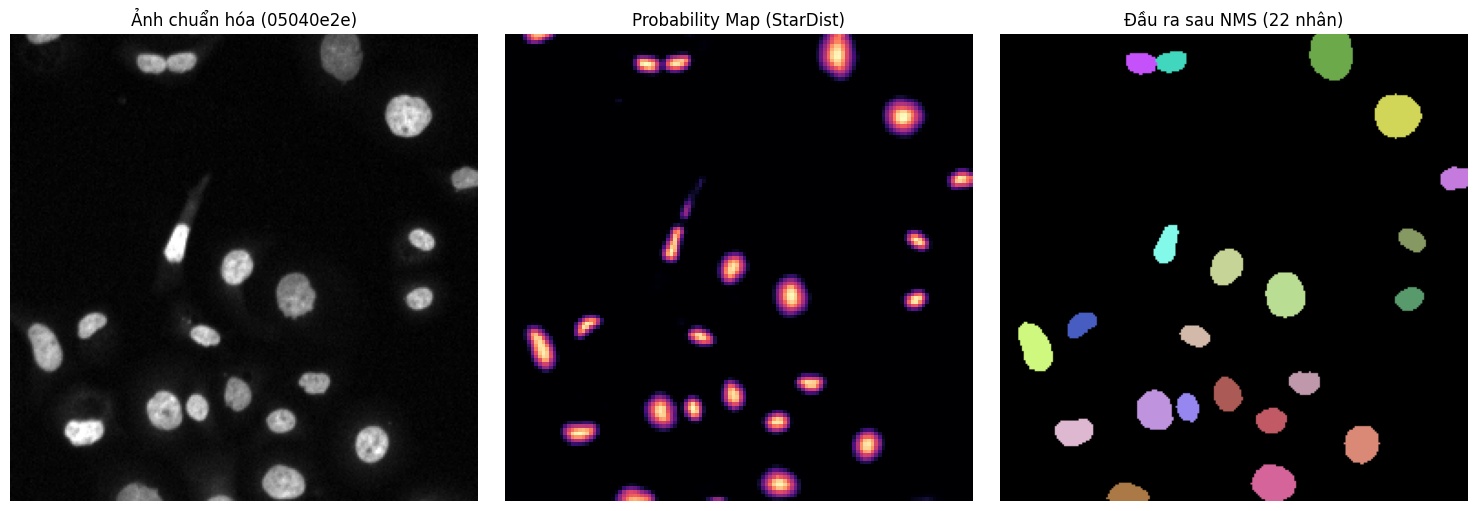

In [10]:
# 10. (Bổ sung cho Chương 2/4) Hình 2.6: Probability Map & Kết quả StarDist
# Chọn ảnh có kích thước chia hết cho 16 (vd: 256x256) để gọi model_pre.predict trực tiếp
div16_indices = [i for i, im in enumerate(X_test) if im.shape[0] % 16 == 0 and im.shape[1] % 16 == 0]
if div16_indices:
    i_prob = div16_indices[0]
    img_p = X_test[i_prob]
    prob, dist = model_pre.predict(img_p)
    lbl_p, details_p = model_pre.predict_instances(img_p)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(img_p, cmap="gray")
    axes[0].set_title(f"Ảnh chuẩn hóa ({test_df.iloc[i_prob]['source_id'][:8]})")
    axes[1].imshow(prob, cmap="magma")
    axes[1].set_title("Probability Map (StarDist)")
    axes[2].imshow(colorize_labels(lbl_p))
    axes[2].set_title(f"Đầu ra sau NMS ({int(lbl_p.max())} nhân)")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.savefig("hinh_2_6_probability_map.png", dpi=300, bbox_inches="tight")
    plt.show()